In [1]:
import torch
from d2l import torch as d2l

In [2]:
X = torch.tensor([[1.0, 2.0, 3.0],[4.0, 5.0, 6.0]])
X.sum(0, keepdim=True), X.sum(1, keepdim=True)

(tensor([[5., 7., 9.]]),
 tensor([[ 6.],
         [15.]]))

In [4]:
def softmax(X):
    X_exp = torch.exp(X)
    partition = X_exp.sum(1, keepdim=True)
    return X_exp / partition

In [6]:
X = torch.rand((2,5))
X_prob = softmax(X)
X_prob, X_prob.sum(1)

(tensor([[0.1472, 0.1948, 0.2036, 0.1530, 0.3013],
         [0.1738, 0.2067, 0.2402, 0.1994, 0.1799]]),
 tensor([1.0000, 1.0000]))

In [7]:
class SoftmaxRegressionScratch(d2l.Classifier):
    def __init__(self, num_inputs, num_outputs, lr, sigma=0.01):
        super().__init__()
        self.save_hyperparameters()
        self.W = torch.normal(0, sigma, size = (num_inputs, num_outputs), requires_grad = True)
        self.b = torch.zeros(num_outputs, requires_grad = True)

    def parameters(self):
        return [self.W, self.b]

In [8]:
@d2l.add_to_class(SoftmaxRegressionScratch)
def forward(self, X):
    X = X.reshape((-1, self.W.shape[0]))
    return softmax(torch.matmul(X, self.W) + self.b)

In [12]:
y = torch.tensor([0,2])
y_hat = torch.tensor([[0.1, 0.3, 0.6],[0.3,0.2, 0.5]])
y_hat[[0,1], y]

tensor([0.1000, 0.5000])

In [13]:
def cross_entropy(y_hat, y):
    return -torch.log(y_hat[list(range(len(y_hat))),y]).mean()

cross_entropy(y_hat, y)

tensor(1.4979)

In [14]:
@d2l.add_to_class(SoftmaxRegressionScratch)
def loss(self, y_hat, y):
    return cross_entropy(y_hat, y)

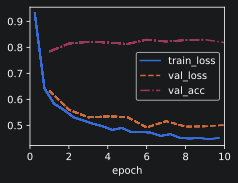

In [15]:
data = d2l.FashionMNIST(batch_size=256)
model = SoftmaxRegressionScratch(num_inputs=784, num_outputs=10, lr=0.1)
trainer = d2l.Trainer(max_epochs=10)
trainer.fit(model,data)

In [16]:
X, y = next(iter(data.val_dataloader()))
preds = model(X).argmax(axis=1)
preds.shape

torch.Size([256])

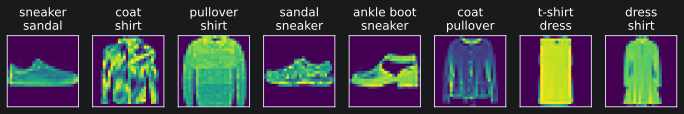

In [17]:
wrong = preds.type(y.dtype) != y
X, y, preds = X[wrong], y[wrong], preds[wrong]
labels = [a+ '\n' +b for a,b in zip(data.text_labels(y), data.text_labels(preds))]
data.visualize([X, y], labels=labels)